# Task 5 · Sales Prediction Using Python

**Track:** Data Science

**Author:** Robin Kumar

**Objective:** Build a regression model that predicts product sales from the money spent on advertising in three media channels: TV, Radio and Newspaper.

**Dataset:** The classic `Advertising.csv` dataset. Each row is one market. The advertising budgets are in thousands of dollars and sales are in thousands of units.

**Steps in this notebook**
1. Import libraries
2. Load the dataset
3. Exploratory Data Analysis (EDA)
4. Sales vs. each advertising channel
5. Correlation matrix heatmap
6. Train / test split
7. Baseline model: Linear Regression
8. Additional model: Random Forest
9. Evaluate the models
10. Residual plot for the best model
11. Which advertising channel has the highest impact on sales?
12. Conclusion

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
blue = "#2a78d6"      # one colour used for all the plots

## 2. Load the dataset

In [2]:
df = pd.read_csv("Advertising.csv")
df.head()

,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


The first column (`Unnamed: 0`) is only a row number from the original file. It carries no information, so it is removed.

In [3]:
df = df.drop(columns=["Unnamed: 0"])
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


## 3. Exploratory Data Analysis (EDA)

### Shape and data types

In [4]:
print("Shape of the dataset:", df.shape)
print()
print(df.dtypes)

Shape of the dataset: (200, 4)

TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object


### Null value check

In [5]:
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated().sum())

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Duplicate rows: 0


### Descriptive statistics

In [6]:
df.describe().round(2)

,TV,Radio,Newspaper,Sales
count,200.00,200.00,200.00,200.00
mean,147.04,23.26,30.55,14.02
std,85.85,14.85,21.78,5.22
min,0.70,0.00,0.30,1.60
25%,74.38,9.98,12.75,10.38
50%,149.75,22.90,25.75,12.90
75%,218.82,36.52,45.10,17.40
max,296.40,49.60,114.00,27.00


### Pairplot of all features

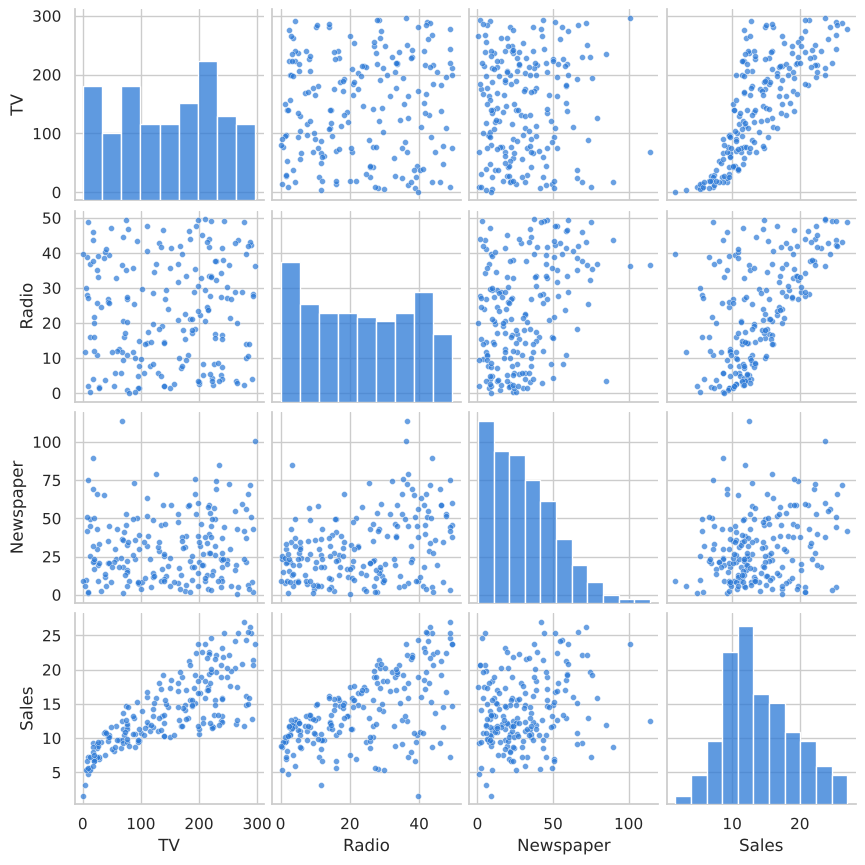

In [7]:
sns.pairplot(df, height=2.2, plot_kws={"color": blue, "s": 18, "alpha": 0.7}, diag_kws={"color": blue})
plt.show()

**Observations from the EDA**

- The dataset has 200 rows and 4 numeric columns: `TV`, `Radio`, `Newspaper` (advertising budgets) and `Sales` (the target).
- There are no null values and no duplicate rows, so no cleaning is needed.
- The TV budget is much larger than the other two. The average TV budget is 147.0, compared with 23.3 for Radio and 30.6 for Newspaper.
- Sales range from 1.6 to 27.0, with an average of 14.0.

## 4. Sales vs. each advertising channel

Each plot shows one channel against sales, with a straight line fitted through the points.

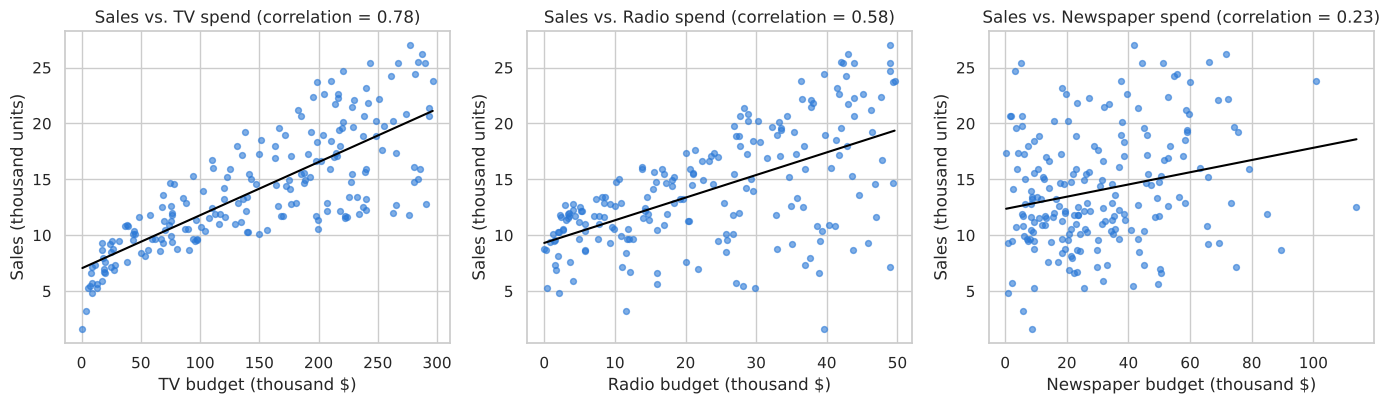

In [8]:
channels = ["TV", "Radio", "Newspaper"]

plt.figure(figsize=(14, 4.2))
for i in range(3):
    channel = channels[i]
    plt.subplot(1, 3, i + 1)
    sns.regplot(x=df[channel], y=df["Sales"], color=blue, ci=None,
                scatter_kws={"s": 18, "alpha": 0.6}, line_kws={"color": "black", "linewidth": 1.5})
    correlation_value = df[channel].corr(df["Sales"])
    plt.title("Sales vs. " + channel + " spend (correlation = " + str(round(correlation_value, 2)) + ")")
    plt.xlabel(channel + " budget (thousand $)")
    plt.ylabel("Sales (thousand units)")
plt.tight_layout()
plt.show()

**Observations from the scatter plots**

- **TV:** sales clearly rise as the TV budget rises (correlation 0.78). The points spread out more at higher budgets, so TV alone does not explain everything.
- **Radio:** sales also rise with the radio budget, but the relationship is weaker (correlation 0.58) and the points are more scattered.
- **Newspaper:** the points form a loose cloud with almost no trend (correlation 0.23). Newspaper spend tells us very little about sales.

## 5. Correlation matrix heatmap

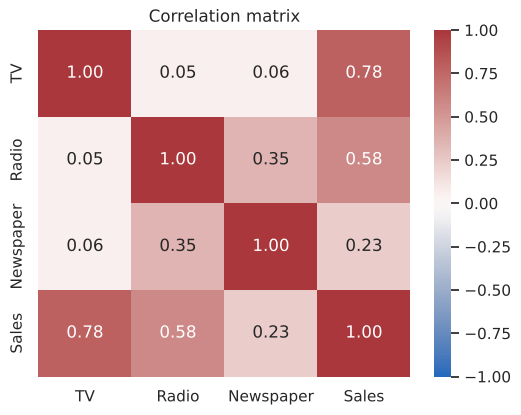

In [9]:
correlation = df.corr()

plt.figure(figsize=(6, 4.5))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()

**Observations from the correlation matrix**

- `TV` has the strongest correlation with `Sales` (0.78), followed by `Radio` (0.58). `Newspaper` is the weakest (0.23).
- The three channels are almost uncorrelated with each other, except `Radio` and `Newspaper` (0.35). Markets that spend more on radio also tend to spend more on newspapers.
- Because of this, part of the newspaper's 0.23 correlation with sales may really come from radio. Section 11 checks this with the model coefficients.

## 6. Train / test split

80% of the rows are used for training and 20% for testing.

In [10]:
X = df[["TV", "Radio", "Newspaper"]]     # input features
y = df["Sales"]                          # target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)

Training set: (160, 3)
Testing set : (40, 3)


## 7. Baseline model: Linear Regression

Linear Regression fits a straight-line formula:

**Sales = intercept + (a × TV) + (b × Radio) + (c × Newspaper)**

It is the baseline: the other model has to beat it to be worth using.

In [11]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)

print("Intercept:", round(linear_model.intercept_, 4))
for i in range(3):
    print("Coefficient of", channels[i], ":", round(linear_model.coef_[i], 4))

Intercept: 2.9791
Coefficient of TV : 0.0447
Coefficient of Radio : 0.1892
Coefficient of Newspaper : 0.0028


## 8. Additional model: Random Forest Regressor

Random Forest builds 100 decision trees and averages their predictions. Unlike Linear Regression, it is not limited to straight lines. It can learn curved relationships and combinations of channels.

In [12]:
forest_model = RandomForestRegressor(n_estimators=100, random_state=42)
forest_model.fit(X_train, y_train)

y_pred_forest = forest_model.predict(X_test)

## 9. Evaluate the models

- **MAE (Mean Absolute Error)**: the average difference between the predicted and the actual sales. Lower is better.
- **RMSE (Root Mean Squared Error)**: like MAE, but large errors are punished more. Lower is better.
- **R² score**: how much of the variation in sales the model explains. 1.0 is perfect.

The R² on the training data is also shown, to check for overfitting.

In [13]:
def evaluate(name, y_pred, train_r2):
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    return [name, mae, rmse, r2, train_r2]


rows = [
    evaluate("Linear Regression", y_pred_linear, linear_model.score(X_train, y_train)),
    evaluate("Random Forest", y_pred_forest, forest_model.score(X_train, y_train)),
]

results = pd.DataFrame(rows, columns=["Model", "MAE", "RMSE", "R2 score", "Train R2 score"])
results = results.sort_values("R2 score", ascending=False).reset_index(drop=True)
results.round(4)

,Model,MAE,RMSE,R2 score,Train R2 score
0,Random Forest,0.6203,0.7687,0.9813,0.9964
1,Linear Regression,1.4608,1.7816,0.8994,0.8957


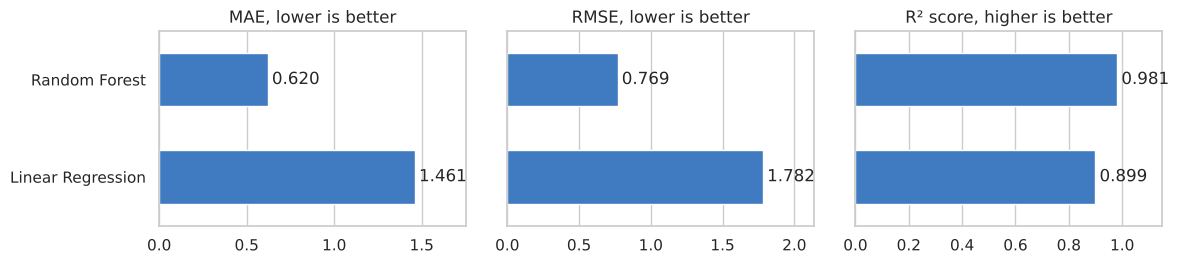

In [14]:
plt.figure(figsize=(12, 2.8))

plt.subplot(1, 3, 1)
ax = sns.barplot(x=results["MAE"], y=results["Model"], color=blue, width=0.55)
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)
plt.title("MAE, lower is better")
plt.xlabel(""); plt.ylabel("")
plt.xlim(0, results["MAE"].max() * 1.2)

plt.subplot(1, 3, 2)
ax = sns.barplot(x=results["RMSE"], y=results["Model"], color=blue, width=0.55)
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)
plt.title("RMSE, lower is better")
plt.xlabel(""); plt.ylabel(""); plt.yticks([])
plt.xlim(0, results["RMSE"].max() * 1.2)

plt.subplot(1, 3, 3)
ax = sns.barplot(x=results["R2 score"], y=results["Model"], color=blue, width=0.55)
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)
plt.title("R² score, higher is better")
plt.xlabel(""); plt.ylabel(""); plt.yticks([])
plt.xlim(0, 1.15)

plt.tight_layout()
plt.show()

In [15]:
best_name = results.loc[0, "Model"]
print("Best-performing model:", best_name)

Best-performing model: Random Forest


### Best model: Random Forest Regressor

**Justification**

1. **Higher R² score (0.981).** It explains about 98% of the variation in sales, compared with about 90% (0.899) for the Linear Regression baseline.
2. **Much lower errors.** Its MAE is 0.620 and its RMSE is 0.769. The baseline's errors are more than twice as large (MAE 1.461, RMSE 1.782).
3. **Only a small sign of overfitting.** The R² is 0.996 on the training data and 0.981 on the test data, so the gap is small.

**Why does it beat the baseline?** Linear Regression can only fit a straight-line formula. Random Forest can also learn curved relationships and combinations of channels, and Section 10 shows that the baseline is missing such a pattern.

**Note:** the test set has only 40 rows, so the exact numbers would change a little with a different split. The gap between the two models is large enough that the ranking is clear.

## 10. Residual plot for the best model

A **residual** is the error of one prediction: actual sales minus predicted sales.

In a good model the residuals are scattered randomly around zero, with no pattern. If they form a curve or a funnel, the model is missing something systematic.

The residuals of the baseline Linear Regression are shown next to the best model for comparison.

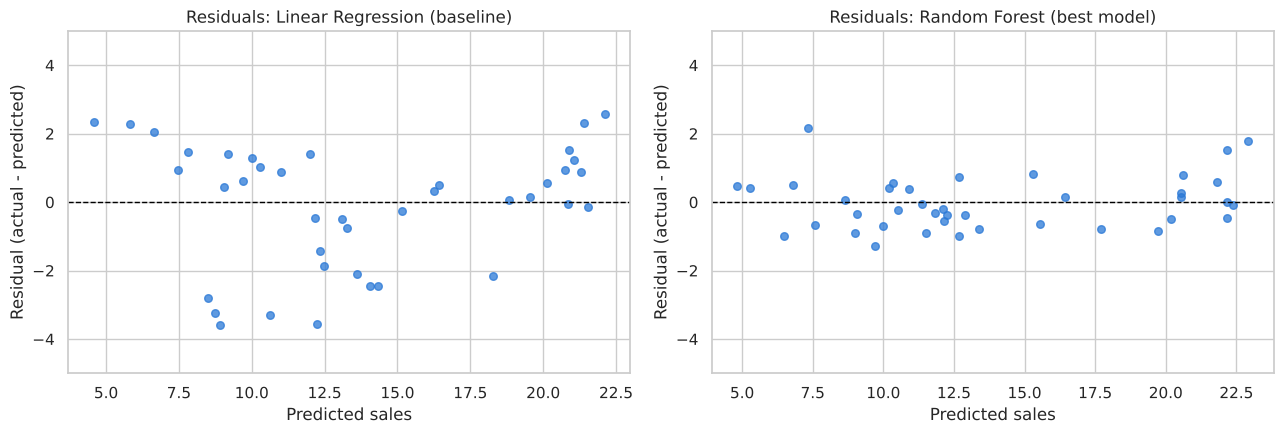

In [16]:
residuals_linear = y_test - y_pred_linear
residuals_forest = y_test - y_pred_forest

plt.figure(figsize=(13, 4.5))

plt.subplot(1, 2, 1)
plt.scatter(y_pred_linear, residuals_linear, color=blue, s=30, alpha=0.75)
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.title("Residuals: Linear Regression (baseline)")
plt.xlabel("Predicted sales")
plt.ylabel("Residual (actual - predicted)")
plt.ylim(-5, 5)

plt.subplot(1, 2, 2)
plt.scatter(y_pred_forest, residuals_forest, color=blue, s=30, alpha=0.75)
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.title("Residuals: Random Forest (best model)")
plt.xlabel("Predicted sales")
plt.ylabel("Residual (actual - predicted)")
plt.ylim(-5, 5)

plt.tight_layout()
plt.show()

In [17]:
# Summary of the residuals of both models
residual_summary = pd.DataFrame({
    "Linear Regression": residuals_linear.describe(),
    "Random Forest": residuals_forest.describe(),
})
residual_summary.round(3)

,Linear Regression,Random Forest
count,40.000,40.000
mean,-0.098,-0.031
std,1.802,0.778
min,-3.603,-1.288
25%,-1.544,-0.647
50%,0.393,-0.142
75%,1.256,0.421
max,2.588,2.156


**Are the errors random or systematic?**

- **Linear Regression (baseline): systematic.** The residuals form a U-shape. They are positive for low and high predictions and mostly negative in the middle. The model under-predicts at both ends and over-predicts in the middle, so it is missing a pattern in the data. The residuals range from -3.6 to +2.6.
- **Random Forest (best model): random.** The residuals are scattered above and below zero with no visible curve, and they are smaller (from -1.3 to +2.2, with a mean of -0.031). This is what the residuals of a well-fitting model should look like.

## 11. Which advertising channel has the highest impact on sales?

This is answered in two ways.

### 11.1 Linear Regression coefficients

A coefficient shows how much sales change when that channel's budget goes up by 1 unit (1 thousand dollars), while the other two budgets stay the same.

In [18]:
coefficients = pd.Series(linear_model.coef_, index=channels)
coefficients.round(4)

TV           0.0447
Radio        0.1892
Newspaper    0.0028
dtype: float64

### 11.2 Random Forest feature importance

Feature importance shows how much the Random Forest relies on each channel to make its predictions. The three values add up to 1.

In [19]:
importance = pd.Series(forest_model.feature_importances_, index=channels)
importance.round(3)

TV           0.625
Radio        0.362
Newspaper    0.013
dtype: float64

In [20]:
impact = pd.DataFrame({
    "Coefficient (per thousand $)": coefficients,
    "Random Forest importance": importance,
    "Average budget (thousand $)": X.mean(),
    "Correlation with Sales": df.corr()["Sales"].drop("Sales"),
})
impact.round(4)

,Coefficient (per thousand $),Random Forest importance,Average budget (thousand $),Correlation with Sales
TV,0.0447,0.6248,147.0425,0.7822
Radio,0.1892,0.3622,23.2640,0.5762
Newspaper,0.0028,0.0130,30.5540,0.2283


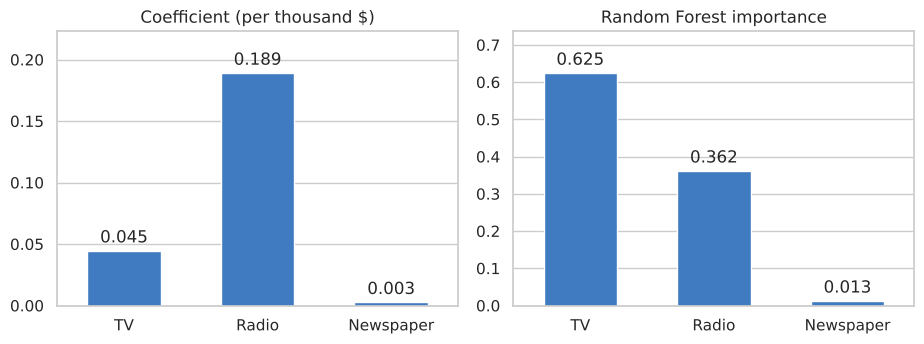

In [21]:
plt.figure(figsize=(9.5, 3.6))
titles = ["Coefficient (per thousand $)", "Random Forest importance"]

for i in range(2):
    plt.subplot(1, 2, i + 1)
    values = impact[titles[i]]
    ax = sns.barplot(x=values.index, y=values.values, color=blue, width=0.55)
    ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)
    plt.title(titles[i])
    plt.xlabel("")
    plt.ylim(0, values.max() * 1.18)

plt.tight_layout()
plt.show()

### Answer

| Channel | Coefficient (per thousand $) | Random Forest importance | Average budget (thousand $) | Correlation with Sales |
|---|---|---|---|---|
| TV | 0.0447 | 0.625 | 147.0 | 0.78 |
| Radio | 0.1892 | 0.362 | 23.3 | 0.58 |
| Newspaper | 0.0028 | 0.013 | 30.6 | 0.23 |

- **TV has the highest overall impact on sales.** It has the highest Random Forest importance (62.5%) and the strongest correlation with sales (0.78). Most of the difference in sales between markets is explained by how much they spend on TV.
- **Radio gives the most sales per dollar.** An extra 1,000 dollars spent on radio adds about 189 units of sales, compared with about 45 units for TV. Radio's coefficient is about four times larger than TV's.
- **Why is TV still first?** The coefficient is the effect of one extra thousand dollars. TV budgets are far larger than radio budgets (147.0 against 23.3 on average), so in total TV accounts for more of the sales.
- **Newspaper has almost no impact.** Its coefficient is close to zero (0.0028) and its importance is only 1.3%. Once TV and radio are taken into account, newspaper adds almost nothing, so its 0.23 correlation with sales is explained by its link with radio, as suspected in Section 5.

**A caution:** these numbers describe this dataset of 200 markets. They show which budgets go together with higher sales, which is strong evidence but not proof of cause and effect.

## 12. Conclusion

- The Advertising dataset has 200 markets with TV, Radio and Newspaper budgets and the resulting sales. It has no null values or duplicates.
- TV has the strongest relationship with sales (correlation 0.78), then Radio (0.58). Newspaper is weak (0.23).
- Two models were trained on an 80/20 split: Linear Regression (baseline) and Random Forest.
- **Random Forest is the best-performing model**, with an R² score of 0.981, an MAE of 0.620 and an RMSE of 0.769. The baseline Linear Regression has an R² of 0.899.
- The residuals of the best model are randomly distributed, while the baseline's residuals show a clear U-shaped pattern.
- **TV has the highest overall impact on sales**, radio gives the most sales per dollar, and newspaper has almost no impact.

**Future improvements:** collect data from more markets, and test whether a model without the Newspaper feature performs just as well.